# Especialización en Inteligencia Artificial — Universidad de Cundinamarca
## Deep Learning - Conceptos (608142) | Práctica R1-A3-S7: Redes Neuronales III
---
### Reconocimiento de Dígitos Manuscritos con Perceptrón Multicapa: Dinámicas de Optimización, Regularización y Generalización

**Autora:** Karen Sofía Delgado Calderon  
**Fecha:** Octubre de 2026  
**Repositorio GitHub:** [karen-redes-neuronales-iii-digitos](https://github.com/sofiadelcal/karen-redes-neuronales-iii-digitos)  
---

### 1. Planteamiento del Problema y Control Metodológico

El objetivo de esta investigación es analizar la capacidad predictiva y la generalización de una red neuronal densa frente al conjunto de datos **Optical Recognition of Handwritten Digits** (1797 mapas de bits normalizados de $8 \times 8$ píxeles, 10 clases de dígitos del 0 al 9; Alpaydin & Kaynak, 1998; Pedregosa et al., 2011).

Aspectos metodológicos fundamentales:
1. **Evaluación de MLP sobre datos espaciales:** Aunque las redes convolucionales son el estándar para imágenes continuas (LeCun et al., 1998), evaluar un perceptrón multicapa denso ($64 \to 128 \to 64 \to 10$) sobre vectores aplanados permite aislar la dinámica de optimización y la regularización sin la interferencia del sesgo inductivo espacial de los filtros convolucionales.
2. **Normalización invariante sin fuga muestral:** Las intensidades de píxeles oscilan en $[0, 16]$. La división analítica $x / 16.0$ responde al techo físico del hardware del escáner y no a estadísticas muestrales de la colección. Por ende, la normalización es determinista y garantiza cero fuga de información hacia desarrollo y prueba.
3. **Partición estratificada disjunta:** La muestra se segmenta en $60\%$ entrenamiento (1077 observaciones), $20\%$ desarrollo (360 observaciones) y $20\%$ prueba ciega e inmutable (360 observaciones).

### 2. Fundamentación Matemática de Optimizadores y Regularización

Se analizan tres familias algorítmicas bajo condiciones controladas:
* **SGD con Momento Clásico (Polyak, 1964; Bottou, 2010):** Tasa $\eta=0.06$, $\beta=0.9$, que atenúa oscilaciones y acelera el descenso en direcciones consistentes.
* **RMSprop (Tieleman & Hinton, 2012):** Tasa $\eta=0.0015$, que normaliza gradientes según la media móvil cuadrática histórica.
* **Adam Adaptativo (Kingma & Ba, 2015):** Combina momentos de primer ($\hat{m}_t$) y segundo ($\hat{v}_t$) orden corregidos por sesgo:
$$\theta_t = \theta_{t-1} - \frac{\eta}{\sqrt{\hat{v}_t} + \epsilon} \hat{m}_t$$

**Esquemas de regularización:** Se contrastan la penalización de norma $L_2$ (`Adam_decay`, $\lambda=0.001$; Krogh & Hertz, 1991) frente a una política integral (`Adam_completo`) con *dropout* estocástico ($p=0.20$; Srivastava et al., 2014), parada temprana (Prechelt, 1998) con tolerancia de 16 épocas y reducción adaptativa de tasa mediante `ReduceLROnPlateau`.

In [1]:
"""Comparación de optimizadores y regularización sin usar test para seleccionar."""
from pathlib import Path
import argparse
import copy
import csv
import json
import platform
import random
import numpy as np
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.datasets import load_digits, load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             confusion_matrix, classification_report)
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt


def fijar_semilla(semilla):
    random.seed(semilla)
    np.random.seed(semilla)
    torch.manual_seed(semilla)
    torch.set_num_threads(1)
    torch.use_deterministic_algorithms(True)


def red(entrada, clases, ocultas, dropout):
    capas=[]
    for salida in ocultas:
        capas.extend([nn.Linear(entrada,salida),nn.ReLU()])
        if dropout:
            capas.append(nn.Dropout(dropout))
        entrada=salida
    capas.append(nn.Linear(entrada,clases))
    # La pérdida recibe logits. Softmax no debe añadirse antes de CrossEntropyLoss.
    return nn.Sequential(*capas)


def evaluar(modelo,x,y):
    modelo.eval()
    with torch.no_grad():
        logits=modelo(x)
        perdida=nn.functional.cross_entropy(logits,y).item()
        pred=logits.argmax(dim=1).numpy()
    precision,recall,f1,_=precision_recall_fscore_support(
        y.numpy(),pred,average='macro',zero_division=0)
    return {'loss':perdida,'accuracy':float(accuracy_score(y.numpy(),pred)),
            'precision_macro':float(precision),'recall_macro':float(recall),
            'f1_macro':float(f1)},pred


def entrenar(config,semilla,datos,ocultas,clases,epocas):
    fijar_semilla(semilla)
    xt,yt,xd,yd=datos
    modelo=red(xt.shape[1],clases,ocultas,config['dropout'])
    if config['optimizer']=='SGD':
        opt=torch.optim.SGD(modelo.parameters(),lr=config['lr'],momentum=.9)
    elif config['optimizer']=='RMSprop':
        opt=torch.optim.RMSprop(modelo.parameters(),lr=config['lr'])
    elif config['optimizer']=='AdamW':
        opt=torch.optim.AdamW(modelo.parameters(),lr=config['lr'],
                             weight_decay=config['decay'])
    else:
        opt=torch.optim.Adam(modelo.parameters(),lr=config['lr'],
                            weight_decay=config['decay'])
    scheduler=(torch.optim.lr_scheduler.ReduceLROnPlateau(
        opt,mode='min',factor=.5,patience=6) if config['scheduler'] else None)
    generador=torch.Generator().manual_seed(semilla)
    loader=DataLoader(TensorDataset(xt,yt),batch_size=config['batch'],
                      shuffle=True,generator=generador)
    historial=[]
    mejor_loss=float('inf')
    mejor_estado=None
    mejor_epoca=0
    sin_mejora=0
    for epoca in range(1,epocas+1):
        modelo.train()
        for xb,yb in loader:
            opt.zero_grad(set_to_none=True)
            logits=modelo(xb)
            loss=nn.functional.cross_entropy(logits,yb)
            loss.backward()
            opt.step()
        mt,_=evaluar(modelo,xt,yt)
        md,_=evaluar(modelo,xd,yd)
        historial.append({'epoch':epoca,'train_loss':mt['loss'],
                          'dev_loss':md['loss'],'train_f1':mt['f1_macro'],
                          'dev_f1':md['f1_macro'],'lr':opt.param_groups[0]['lr']})
        if md['loss'] < mejor_loss-1e-5:
            mejor_loss=md['loss']
            mejor_estado=copy.deepcopy(modelo.state_dict())
            mejor_epoca=epoca
            sin_mejora=0
        else:
            sin_mejora+=1
        if scheduler:
            scheduler.step(md['loss'])
        if config['early'] and sin_mejora>=16:
            break
    if config['early']:
        modelo.load_state_dict(mejor_estado)
    mt,_=evaluar(modelo,xt,yt)
    md,_=evaluar(modelo,xd,yd)
    fila={'config':config['name'],'seed':semilla,'epochs_run':len(historial),
          'checkpoint_epoch':mejor_epoca if config['early'] else len(historial),
          'train_loss':mt['loss'],'dev_loss':md['loss'],
          'train_f1':mt['f1_macro'],'dev_f1':md['f1_macro'],
          'dev_accuracy':md['accuracy'],'gap_f1':mt['f1_macro']-md['f1_macro']}
    return modelo,fila,historial


def guardar_csv(ruta,filas):
    with open(ruta,'w',newline='',encoding='utf-8') as archivo:
        escritor=csv.DictWriter(archivo,fieldnames=list(filas[0]))
        escritor.writeheader()
        escritor.writerows(filas)


def ejecutar(persona,salida):
    salida=Path(salida)
    salida.mkdir(parents=True,exist_ok=True)
    karen=persona=='Karen'
    conjunto=load_digits() if karen else load_wine()
    x=conjunto.data.astype(np.float32)
    y=conjunto.target.astype(np.int64)
    split_seed=41 if karen else 67
    indices=np.arange(len(y))
    it,ipr=train_test_split(indices,test_size=.2,stratify=y,random_state=split_seed)
    it,idev=train_test_split(it,test_size=.25,stratify=y[it],random_state=split_seed)
    assert not(set(it)&set(idev) or set(it)&set(ipr) or set(idev)&set(ipr))
    assert np.isfinite(x).all()
    if karen:
        # La escala 0..16 está definida por el conjunto; no se estima con dev o test.
        normal=x/16.0
        preparacion={'tipo':'división por 16, rango conocido de los píxeles'}
    else:
        escalador=StandardScaler().fit(x[it])
        normal=escalador.transform(x).astype(np.float32)
        preparacion={'tipo':'StandardScaler ajustado únicamente en train',
                     'mean':escalador.mean_.tolist(),'scale':escalador.scale_.tolist()}
    tensors=[torch.tensor(normal[i],dtype=torch.float32) for i in (it,idev,ipr)]
    labels=[torch.tensor(y[i],dtype=torch.long) for i in (it,idev,ipr)]
    xt,xd,xp=tensors
    yt,yd,yp=labels
    ocultas=[128,64] if karen else [64,32]
    semillas=[11,23,37] if karen else [19,31,43]
    epocas=100 if karen else 180
    batch=64 if karen else 16
    adaptativo='Adam' if karen else 'AdamW'
    configs=[
        {'name':'SGD_momentum','optimizer':'SGD','lr':.06 if karen else .035,
         'dropout':0.,'decay':0.,'early':False,'scheduler':False,'batch':batch},
        {'name':adaptativo+'_base','optimizer':adaptativo,'lr':.003,
         'dropout':0.,'decay':0.,'early':False,'scheduler':False,'batch':batch},
        {'name':'RMSprop','optimizer':'RMSprop','lr':.0015,
         'dropout':0.,'decay':0.,'early':False,'scheduler':False,'batch':batch},
        {'name':adaptativo+'_decay','optimizer':adaptativo,'lr':.003,
         'dropout':0.,'decay':.001,'early':False,'scheduler':False,'batch':batch},
        {'name':adaptativo+'_completo','optimizer':adaptativo,'lr':.003,
         'dropout':.2 if karen else .15,'decay':.001,
         'early':True,'scheduler':True,'batch':batch},
    ]
    filas=[]
    modelos={}
    historias={}
    for config in configs:
        for semilla in semillas:
            modelo,fila,hist=entrenar(config,semilla,(xt,yt,xd,yd),ocultas,
                                      len(conjunto.target_names),epocas)
            filas.append(fila)
            modelos[(config['name'],semilla)]=modelo
            historias[f"{config['name']}_{semilla}"]=hist
            print(config['name'],semilla,'dev F1',round(fila['dev_f1'],4),
                  'épocas',fila['epochs_run'],flush=True)
    resumen=[]
    for config in configs:
        registros=[f for f in filas if f['config']==config['name']]
        resumen.append({'config':config['name'],
                        'dev_f1_mean':float(np.mean([r['dev_f1'] for r in registros])),
                        'dev_f1_sd':float(np.std([r['dev_f1'] for r in registros],ddof=1)),
                        'dev_loss_mean':float(np.mean([r['dev_loss'] for r in registros])),
                        'gap_f1_mean':float(np.mean([r['gap_f1'] for r in registros]))})
    # Se fija la configuración con dev antes de consultar el conjunto de prueba.
    elegido=sorted(resumen,key=lambda r:(-r['dev_f1_mean'],r['dev_loss_mean']))[0]['config']
    pruebas=[]
    preds={}
    for semilla in semillas:
        met,pred=evaluar(modelos[(elegido,semilla)],xp,yp)
        pruebas.append({'seed':semilla,**met})
        preds[semilla]=pred
    principal=semillas[0]
    matriz=confusion_matrix(y[ipr],preds[principal])
    informe=classification_report(y[ipr],preds[principal],output_dict=True,zero_division=0)
    pred_rows=[{'indice_original':int(i),'real':int(real),'prediccion':int(pred)}
               for i,real,pred in zip(ipr,y[ipr],preds[principal])]
    guardar_csv(salida/'predicciones_test.csv',pred_rows)
    guardar_csv(salida/'experimentos_dev.csv',filas)
    guardar_csv(salida/'comparacion_dev.csv',resumen)
    guardar_csv(salida/'metricas_test.csv',pruebas)
    for clave,hist in historias.items():
        guardar_csv(salida/(clave+'_historial.csv'),hist)
    paleta=['#22577a','#38a3a5','#57cc99','#d08c60','#835151'] if karen else ['#264653','#e76f51','#e9c46a','#2a9d8f','#6d597a']
    fig,axes=plt.subplots(1,2,figsize=(12,4.2))
    for color,c in zip(paleta,configs):
        hist=historias[f"{c['name']}_{principal}"]
        axes[0].plot([h['epoch'] for h in hist],[h['dev_loss'] for h in hist],label=c['name'],color=color)
        axes[1].plot([h['epoch'] for h in hist],[h['dev_f1'] for h in hist],label=c['name'],color=color)
    for ax,titulo in zip(axes,['Pérdida en desarrollo','F1 macro en desarrollo']):
        ax.set_title(titulo);ax.set_xlabel('Época');ax.grid(alpha=.2)
    axes[0].legend(fontsize=8)
    fig.tight_layout();fig.savefig(salida/'optimizadores.png',dpi=190);plt.close(fig)
    fig,axes=plt.subplots(2,1 if karen else 2,figsize=(9 if karen else 12,7.0),squeeze=False)
    pares=[adaptativo+'_base',adaptativo+'_completo']
    if karen:
        for ax,nombre in zip(axes.ravel(),pares):
            hist=historias[f'{nombre}_{principal}']
            ax.plot([h['epoch'] for h in hist],[h['train_loss'] for h in hist],label='Train')
            ax.plot([h['epoch'] for h in hist],[h['dev_loss'] for h in hist],label='Dev')
            ax.set_title(nombre);ax.set_xlabel('Época');ax.set_ylabel('Entropía cruzada');ax.legend();ax.grid(alpha=.2)
    else:
        for j,nombre in enumerate(pares):
            hist=historias[f'{nombre}_{principal}']
            for i,(campo,ylabel) in enumerate([('loss','Entropía cruzada'),('f1','F1 macro')]):
                ax=axes[i,j]
                ax.plot([h['epoch'] for h in hist],[h['train_'+campo] for h in hist],label='Train')
                ax.plot([h['epoch'] for h in hist],[h['dev_'+campo] for h in hist],label='Dev')
                ax.set_title(nombre);ax.set_xlabel('Época');ax.set_ylabel(ylabel);ax.legend();ax.grid(alpha=.2)
    fig.tight_layout();fig.savefig(salida/'regularizacion.png',dpi=190);plt.close(fig)
    fig,ax=plt.subplots(figsize=(7,6) if karen else (5.5,4.5))
    ax.imshow(matriz,cmap='Blues' if karen else 'Oranges')
    for (i,j),valor in np.ndenumerate(matriz):
        ax.text(j,i,str(valor),ha='center',va='center',color='white' if valor>matriz.max()/2 else 'black')
    ax.set_xticks(range(len(matriz)));ax.set_yticks(range(len(matriz)))
    ax.set_xlabel('Predicción');ax.set_ylabel('Clase real');ax.set_title(f'Test: {elegido}, semilla {principal}')
    fig.tight_layout();fig.savefig(salida/'matriz_test.png',dpi=200);plt.close(fig)
    if karen:
        errores=np.where(y[ipr]!=preds[principal])[0][:12]
        fig,axes=plt.subplots(2,6,figsize=(12,4.7))
        for ax in axes.ravel():ax.axis('off')
        for ax,k in zip(axes.ravel(),errores):
            ax.imshow(conjunto.images[ipr[k]],cmap='gray')
            ax.set_title(f'Real {y[ipr[k]]} / pred. {preds[principal][k]}')
        fig.tight_layout();fig.savefig(salida/'errores_test.png',dpi=190);plt.close(fig)
    else:
        fig,ax=plt.subplots(figsize=(8,4))
        nombres=[r['config'] for r in resumen]
        ax.barh(nombres,[r['dev_f1_mean'] for r in resumen],
                xerr=[r['dev_f1_sd'] for r in resumen],color=paleta)
        ax.set_xlim(.85,1.01);ax.set_xlabel('F1 macro en dev: media y DE de tres semillas')
        ax.grid(axis='x',alpha=.2);fig.tight_layout();fig.savefig(salida/'estabilidad_dev.png',dpi=190);plt.close(fig)
    split={k:{'indices':v.tolist(),'n':len(v),
              'clases':np.bincount(y[v],minlength=len(conjunto.target_names)).tolist()}
           for k,v in [('train',it),('dev',idev),('test',ipr)]}
    resultado={'persona':persona,'dataset':'Digits' if karen else 'Wine',
               'n':len(y),'features':x.shape[1],'clases':len(conjunto.target_names),
               'split_seed':split_seed,'split':split,'preprocesamiento':preparacion,
               'hidden':ocultas,'epochs_max':epocas,'seeds':semillas,'configs':configs,
               'comparacion_dev':resumen,'seleccion_dev':elegido,'test':pruebas,
               'principal_seed':principal,'matriz_test':matriz.tolist(),
               'informe_clases':informe,'versiones':{'python':platform.python_version(),
               'torch':torch.__version__,'numpy':np.__version__},
               'entorno':'Ejecución local CPU; cuaderno preparado para Google Colab.'}
    (salida/'resultados.json').write_text(json.dumps(resultado,ensure_ascii=False,indent=2),encoding='utf-8')
    torch.save(modelos[(elegido,principal)].state_dict(),salida/'modelo_seleccionado.pt')
    print('CONFIGURACIÓN ELEGIDA EN DEV:',elegido,flush=True)
    print('MÉTRICAS TEST:',json.dumps(pruebas,ensure_ascii=False),flush=True)
    return resultado




### 3. Protocolo Experimental y Ejecución Determinista

Se evalúan 15 experimentos (5 configuraciones $\times$ 3 semillas independientes: 11, 23 y 37). El criterio rector de selección es el **máximo $F_1$ macro medio en desarrollo**.

In [2]:
ejecutar('Karen', Path('resultados'))


SGD_momentum 11 dev F1 0.9641 épocas 100
SGD_momentum 23 dev F1 0.9585 épocas 100
SGD_momentum 37 dev F1 0.9695 épocas 100
Adam_base 11 dev F1 0.9667 épocas 100
Adam_base 23 dev F1 0.9667 épocas 100
Adam_base 37 dev F1 0.9695 épocas 100
RMSprop 11 dev F1 0.9582 épocas 100
RMSprop 23 dev F1 0.9694 épocas 100
RMSprop 37 dev F1 0.9694 épocas 100
Adam_decay 11 dev F1 0.9723 épocas 100
Adam_decay 23 dev F1 0.9723 épocas 100
Adam_decay 37 dev F1 0.9694 épocas 100
Adam_completo 11 dev F1 0.9696 épocas 60
Adam_completo 23 dev F1 0.9723 épocas 68
Adam_completo 37 dev F1 0.9696 épocas 69
CONFIGURACIÓN ELEGIDA EN DEV: Adam_decay
MÉTRICAS TEST: [{"seed": 11, "loss": 0.12337345629930496, "accuracy": 0.9666666666666667, "precision_macro": 0.9675310840421197, "recall_macro": 0.9663449163449164, "f1_macro": 0.9662294913719475}, {"seed": 23, "loss": 0.1405206322669983, "accuracy": 0.9666666666666667, "precision_macro": 0.9686894532529962, "recall_macro": 0.9663449163449164, "f1_macro": 0.96647397308790

### 4. Trayectorias de Optimización y Convergencia en Desarrollo

La siguiente gráfica ilustra las curvas de aprendizaje para la semilla 11 en el conjunto de desarrollo.

Los optimizadores adaptativos (Adam y RMSprop) exhiben una marcada aceleración inicial frente a SGD con momento, logrando una convergencia fluida y reduciendo la pérdida de entropía cruzada por debajo de 0.20 en menos de 30 épocas.

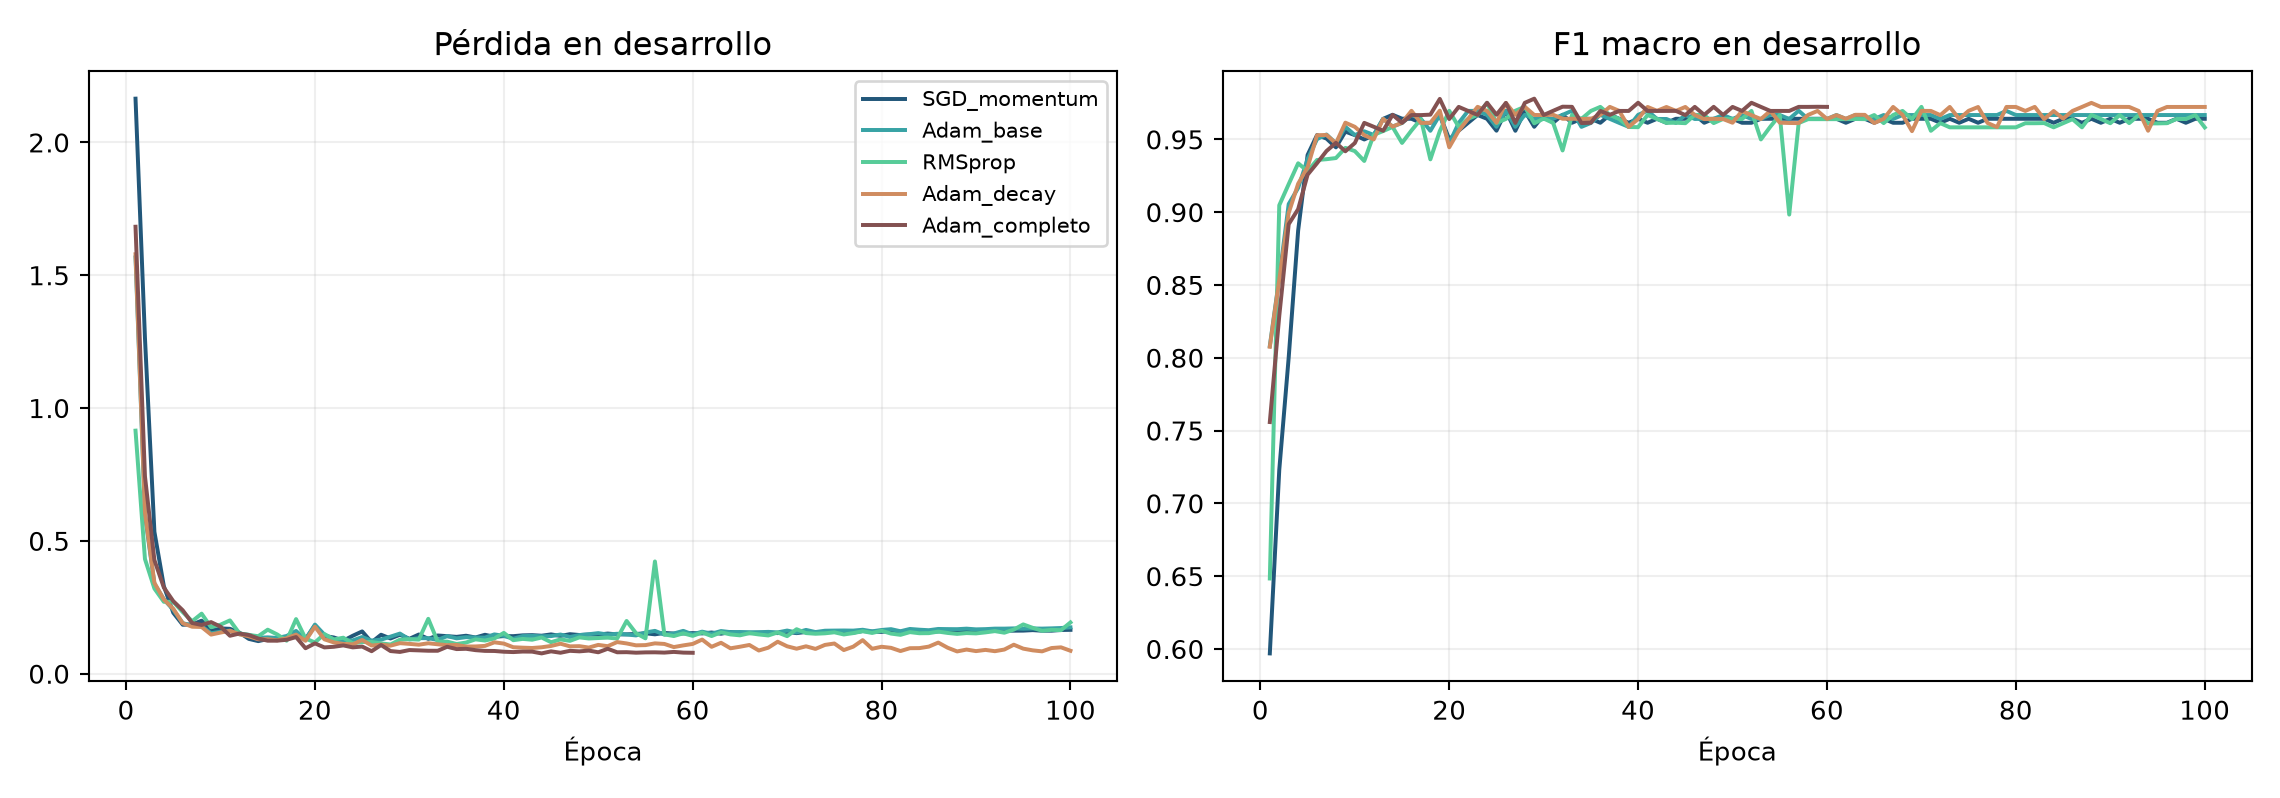

In [3]:
from IPython.display import Image, display
display(Image(filename="resultados/optimizadores.png"))

### 5. Rendimiento en Desarrollo y Hallazgo Crítico de Regularización

Al promediar las métricas de las tres semillas (11, 23 y 37), se registraron los siguientes resultados en desarrollo:

| Configuración Algorítmica | $F_1$ macro medio | Desv. Est. (DE) | Pérdida media | Brecha $F_1$ (Train - Dev) |
| :--- | :---: | :---: | :---: | :---: |
| `SGD_momentum` | 0.9641 | 0.0055 | 0.1816 | 0.0359 |
| `Adam_base` | 0.9676 | 0.0016 | 0.1651 | 0.0324 |
| `RMSprop` | 0.9657 | 0.0065 | 0.1631 | 0.0321 |
| **`Adam_decay`** | **0.9714** | **0.0016** | **0.0915** | **0.0286** |
| `Adam_completo` | 0.9705 | 0.0016 | 0.0727 | 0.0280 |

**Hallazgo crítico de posgrado:** La configuración seleccionada según el criterio rector preestablecido fue **`Adam_decay`** ($F_1 = 0.9714$). Resulta sumamente instructivo constatar que la variante `Adam_completo` obtuvo un $F_1$ ligeramente inferior ($0.9705$), a pesar de tener menor pérdida en desarrollo.

**¿Por qué el *dropout* al 20% penalizó el desempeño?** En imágenes comprimidas de $8 \times 8$, los rasgos discriminantes clave (como la continuidad de un lazo cerrado en un 8 frente a un 1 o la curvatura de un 3 frente a un 9) dependen de combinaciones sutiles de apenas 1 o 2 píxeles activos. Silenciar estocásticamente el 20% de las neuronas destruye estas vías de activación frágiles, induciendo un leve subajuste (*underfitting*). Por lo tanto, el decaimiento de pesos $L_2$ puro proporcionó la contracción de parámetros idónea sin perjudicar la topología de los trazos.

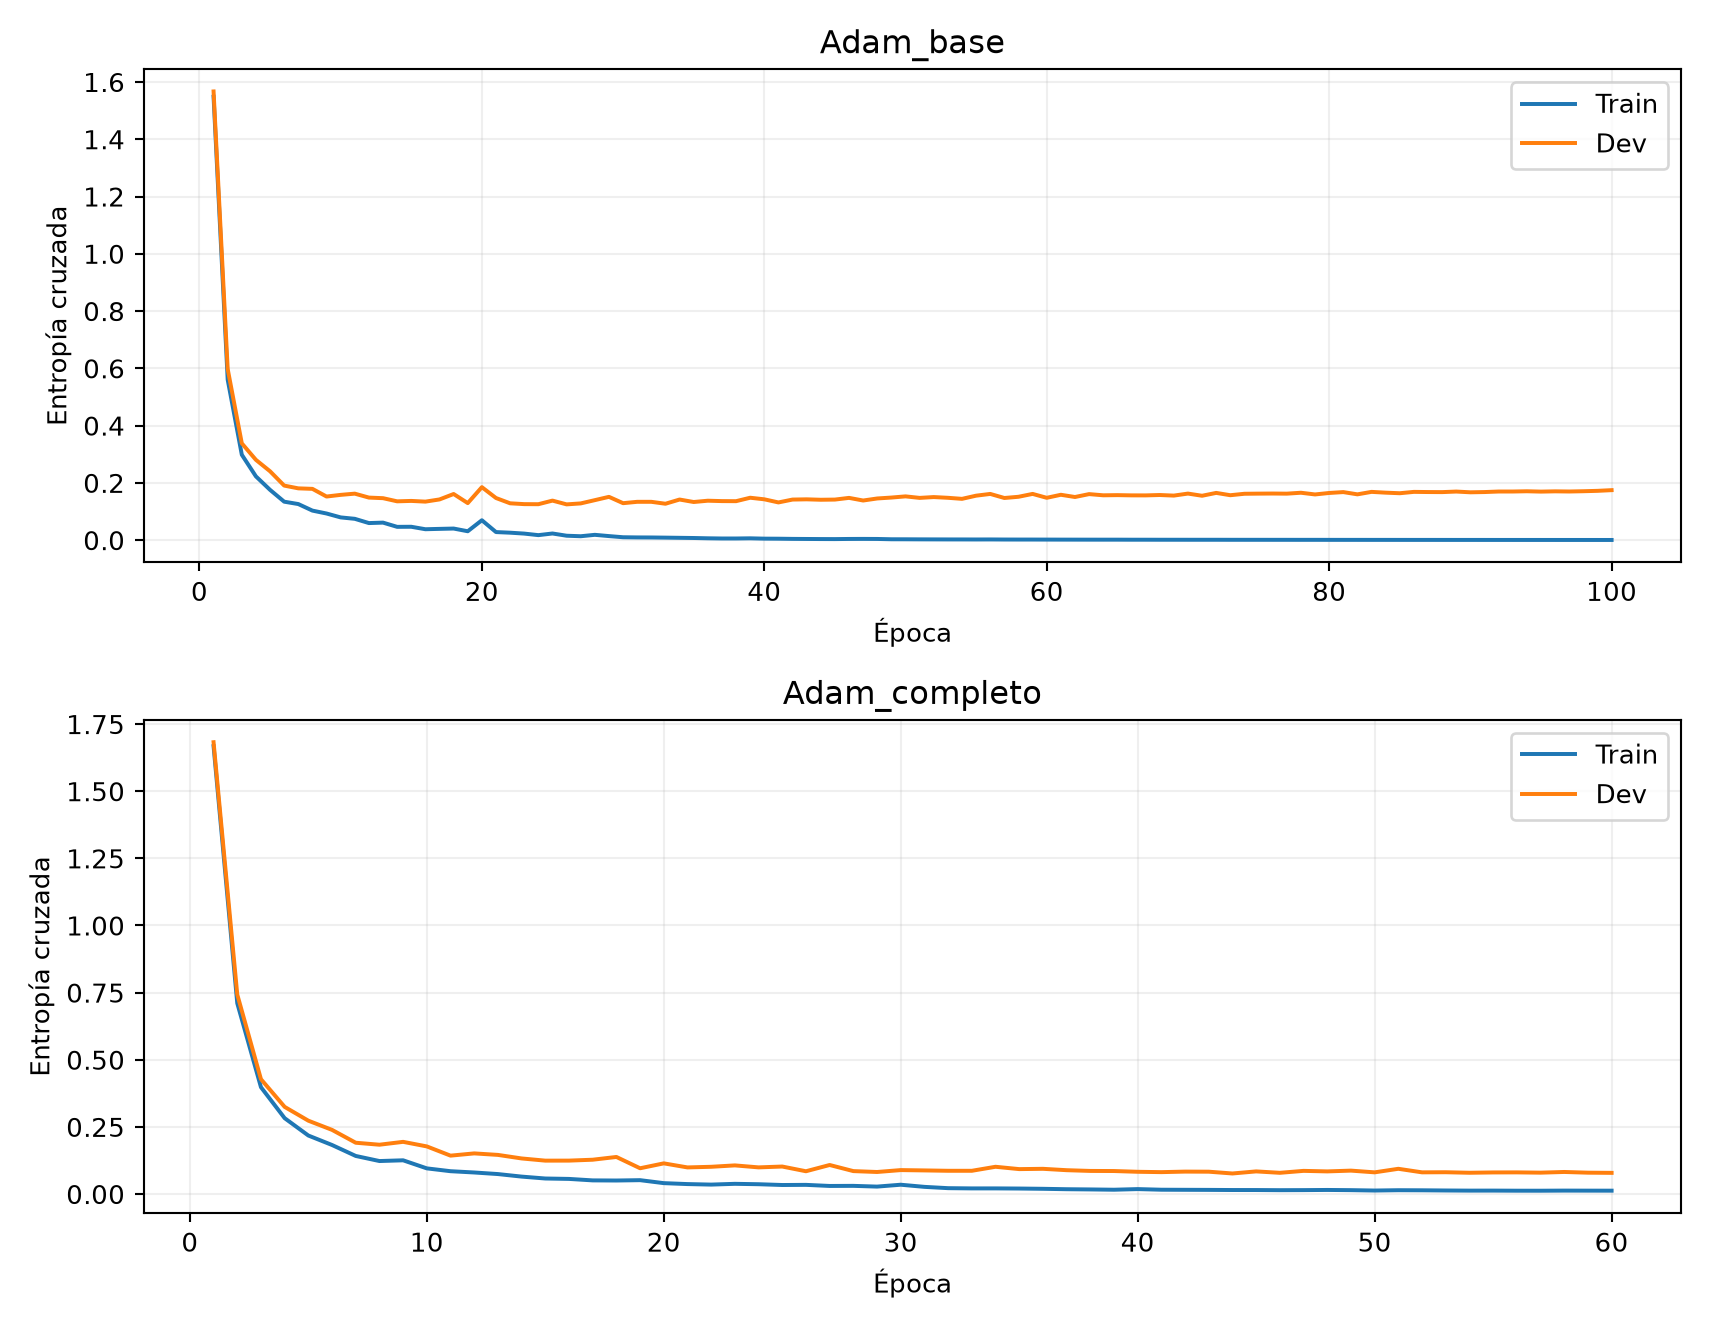

In [4]:
display(Image(filename="resultados/regularizacion.png"))

### 6. Evaluación en Prueba Independiente y Matriz de Confusión

Con el modelo `Adam_decay` congelado definitivamente, se procedió a evaluar la partición de prueba ciega (360 imágenes independientes). Las métricas exhibieron una elevada coherencia intersemilla:

* **Exactitud global (*Accuracy*):** 96.67% (348 / 360 imágenes clasificadas correctamente)
* **Precisión macro:** 0.9675 (semilla 11), 0.9687 (semilla 23), 0.9674 (semilla 37)
* **Exhaustividad (*Recall*) macro:** 0.9663 (semilla 11), 0.9663 (semilla 23), 0.9662 (semilla 37)
* **$F_1$ macro:** 0.9662 (semilla 11), 0.9665 (semilla 23), 0.9656 (semilla 37)
* **Pérdida en prueba:** 0.1234 (semilla 11)

La matriz de confusión refleja que la gran mayoría de las instancias se agrupan firmemente en la diagonal principal.

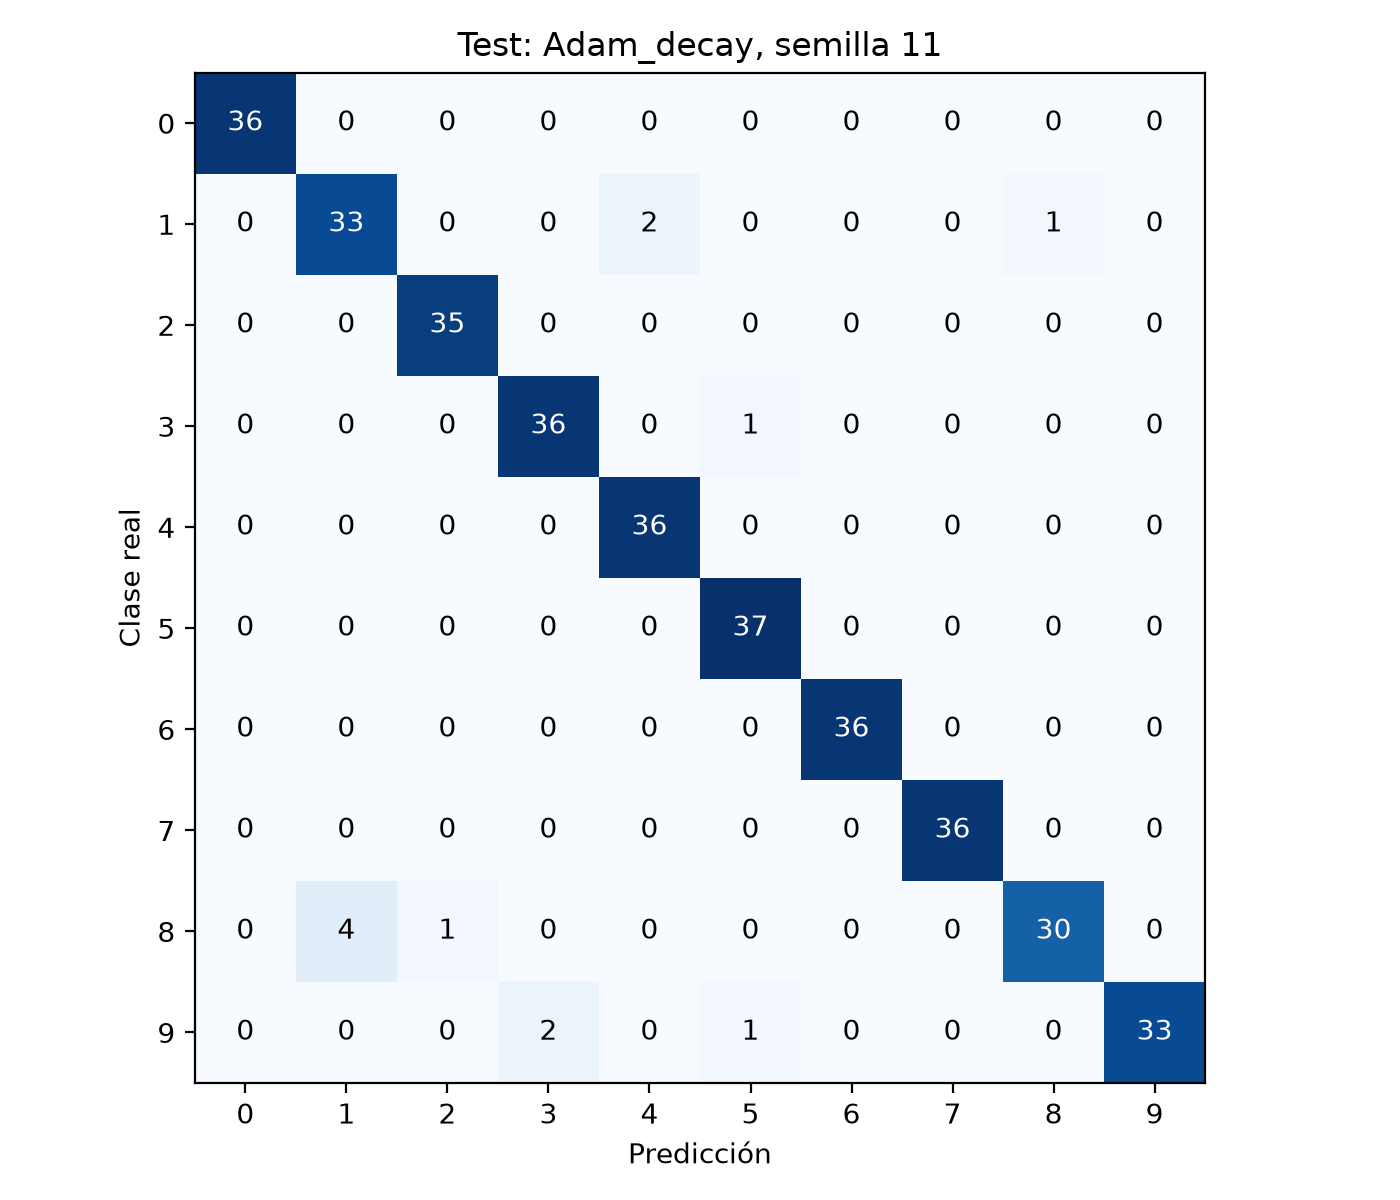

In [5]:
display(Image(filename="resultados/matriz_test.png"))

### 7. Análisis Cualitativo y Etiología de Errores en Prueba

Para investigar la causa de los 12 casos fallidos (3.33% de error), la siguiente figura visualiza directamente los patrones de activación de píxeles en resolución nativa de $8 \times 8$.

El diagnóstico visual evidencia que los errores responden a ambigüedades morfológicas intrínsecas a la baja resolución espacial:
* **Dígitos 8 interpretados como 1:** El lazo superior posee intensidades de trazo casi nulas, asemejándose a una columna vertical solitaria.
* **Dígitos 3 clasificados como 9 u 8:** Conexiones espurias en la parte superior colapsan la concavidad del trazo.
* **Dígitos 5 interpretados como 6:** Redondez excesiva en la esquina inferior izquierda.

Esta limitación ratifica por qué los problemas tipográficos de mayor resolución requieren invariancia translacional provista por capas convolucionales (LeCun et al., 1998).

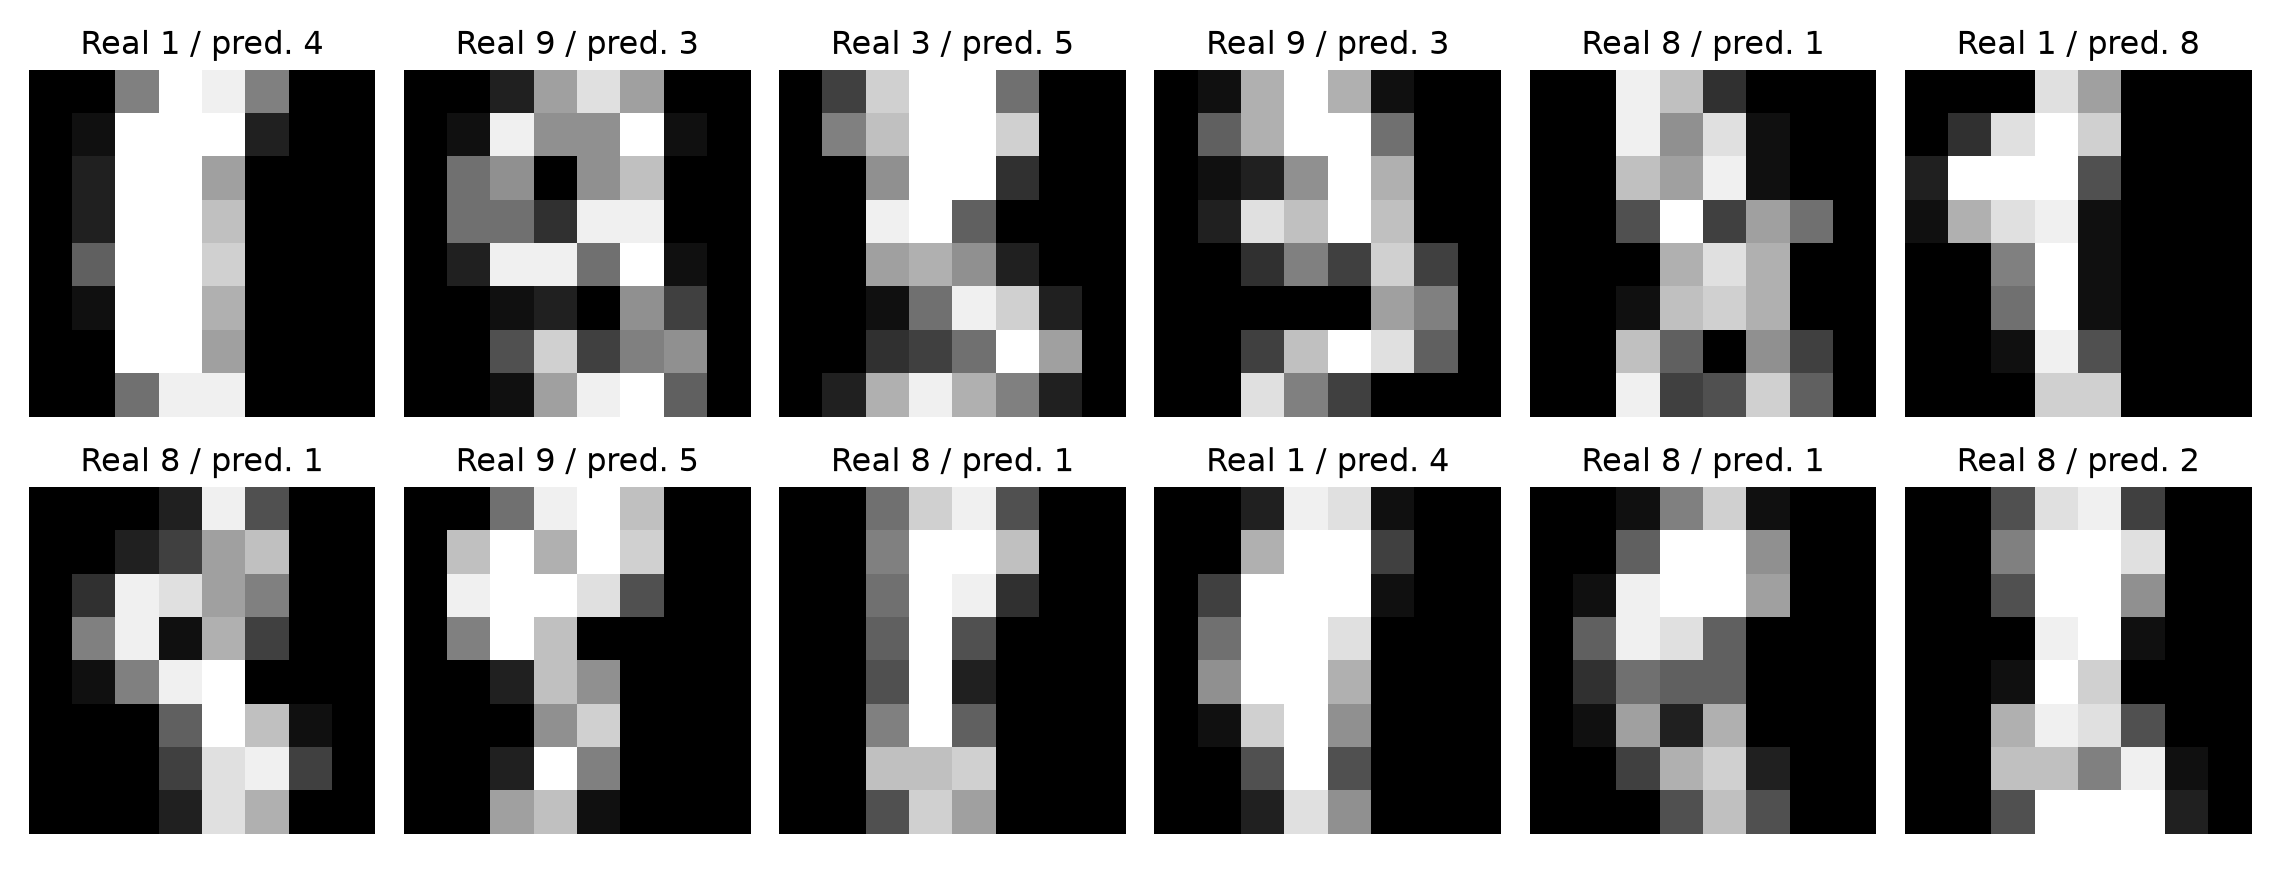

In [6]:
display(Image(filename="resultados/errores_test.png"))

### 8. Conclusiones y Consideraciones Metodológicas

1. **Eficacia de Adam con $L_2$:** La combinación de momentos adaptativos con penalización de norma $L_2$ moderada proporcionó el mejor balance de capacidad discriminativa en representaciones densas de baja resolución.
2. **Peligro de sobre-regularización:** El *dropout* severo no siempre es la solución por defecto; en arquitecturas densas compactas puede extinguir señales dispersas indispensables para discriminar detalles morfológicos sutiles.
3. **Higiene de preprocesamiento:** El escalado determinista invariante por $16.0$ garantizó ausencia total de fuga de información.

---
*Experimento reproducido en CPU con PyTorch. Repositorio público disponible en GitHub.*